# Regression: OLS → Ridge → Lasso → PCA

**Pipeline:**
1. **Look at the data**: target distribution, feature correlations.
2. **Split and set a baseline.** Every model must beat "predict the mean".
3. **OLS**: the reference linear model.
4. **Ridge** (L2): shrinks all coefficients. Helps with correlated features.
5. **Lasso** (L1): shrinks some coefficients to exactly 0, so it does **feature selection**.
6. **PCA + OLS** (principal component regression): replaces correlated features with a few uncorrelated components.
7. **Compare with cross-validation**, then score the chosen model once on the test set.

The dataset is scikit-learn's *diabetes* set: 442 patients, 10 features, and a target measuring disease progression after one year.
To use your own data, replace the load cell with `df = pd.read_csv(...)`, `X = df.drop(columns="target")`, `y = df["target"]`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, r2_score

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(10, 4))

## 1. Load and look

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
df = X.assign(target=y)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


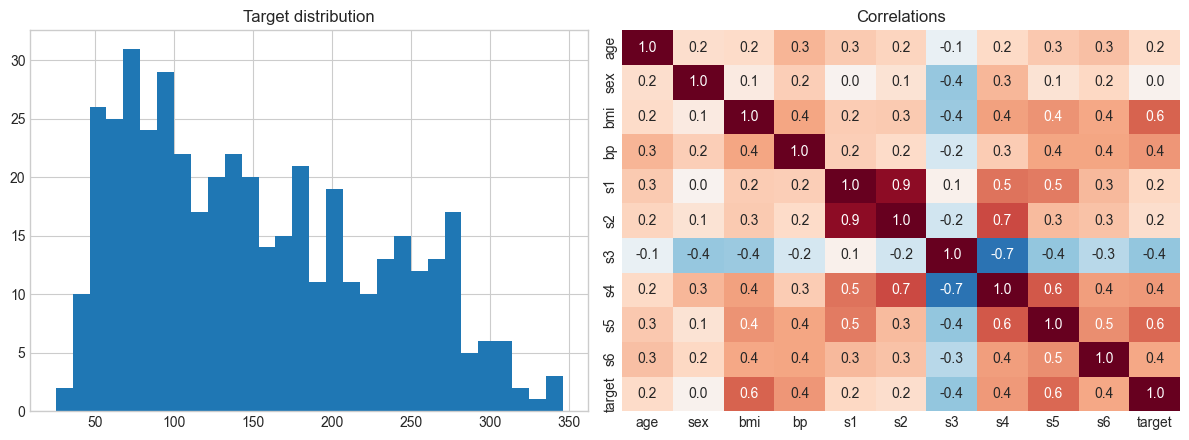

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
y.hist(bins=30, ax=ax1); ax1.set_title("Target distribution")
sns.heatmap(df.corr(), cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax2, cbar=False)
ax2.set_title("Correlations");

What to look for:
- **Skewed target?** Try modelling `np.log1p(y)`.
- **Strongly correlated features** (s1/s2 here). OLS coefficients become unstable, and Ridge or PCA usually help.
- **Features most correlated with the target** are the ones you'd expect Lasso to keep.

## 2. Split and baseline

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

baseline = np.full(len(y_test), y_train.mean())
print(f"Baseline RMSE (predict the mean): {root_mean_squared_error(y_test, baseline):.1f}")

Baseline RMSE (predict the mean): 71.7


Each model below sits in a **pipeline** with `StandardScaler`:
- Ridge, Lasso and PCA all depend on feature scale, so put the features on a common scale first.
- Inside a pipeline the scaler is fit only on the training folds, which avoids leakage.

We compare models with 5-fold CV RMSE on the training set.

In [5]:
def cv_rmse(model):
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean()

results = {}

## 3. OLS

OLS CV RMSE: 53.7


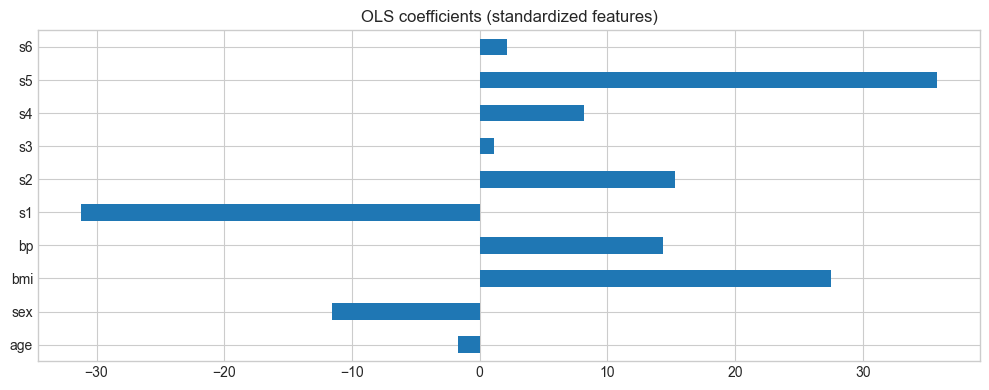

In [6]:
from sklearn.linear_model import LinearRegression

ols = make_pipeline(StandardScaler(), LinearRegression())
results["OLS"] = cv_rmse(ols)
print(f"OLS CV RMSE: {results['OLS']:.1f}")

ols.fit(X_train, y_train)
coefs = pd.DataFrame({"OLS": ols[-1].coef_}, index=X.columns)
coefs.plot.barh(title="OLS coefficients (standardized features)", legend=False);

## 4. Ridge: L2 penalty
Ridge minimizes `RSS + α·Σβ²`. A larger α shrinks every coefficient toward 0 without making any of them exactly 0.
Choose α by cross-validation over a log-spaced grid.

In [7]:
from sklearn.linear_model import Ridge

alphas = np.logspace(-3, 3, 50)
ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": alphas},
    cv=5, scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)

best_alpha = ridge_search.best_params_["ridge__alpha"]
results["Ridge"] = -ridge_search.best_score_
print(f"Ridge best alpha = {best_alpha:.3g},  CV RMSE: {results['Ridge']:.1f}")

Ridge best alpha = 11,  CV RMSE: 53.6


**Coefficient path:** how each coefficient changes as α grows.

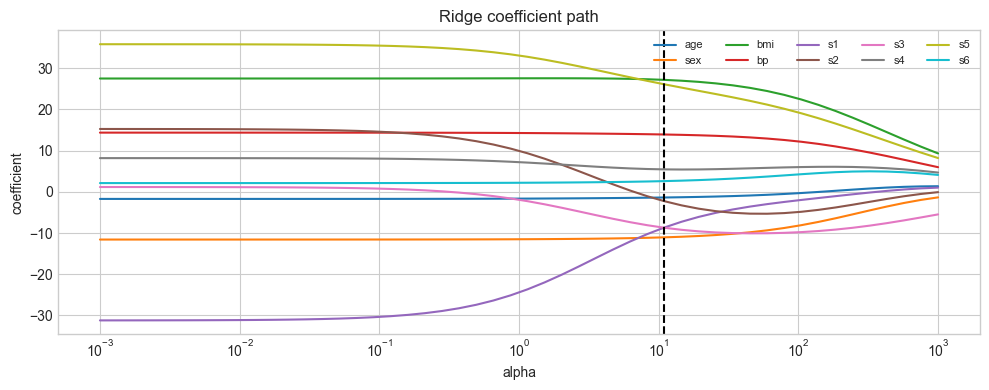

In [8]:
X_std = StandardScaler().fit_transform(X_train)
path = pd.DataFrame([Ridge(alpha=a).fit(X_std, y_train).coef_ for a in alphas], index=alphas, columns=X.columns)

ax = path.plot(logx=True, title="Ridge coefficient path")
ax.axvline(best_alpha, ls="--", color="k")
ax.set(xlabel="alpha", ylabel="coefficient")
ax.legend(ncol=5, fontsize=8);

## 5. Lasso: L1 penalty
Lasso minimizes `RSS + α·Σ|β|`. The L1 penalty drives weak coefficients to **exactly zero**, so the model selects its own features.
`LassoCV` searches for α itself.

Lasso best alpha = 0.417,  CV RMSE: 53.7
Features dropped by Lasso: ['s2']


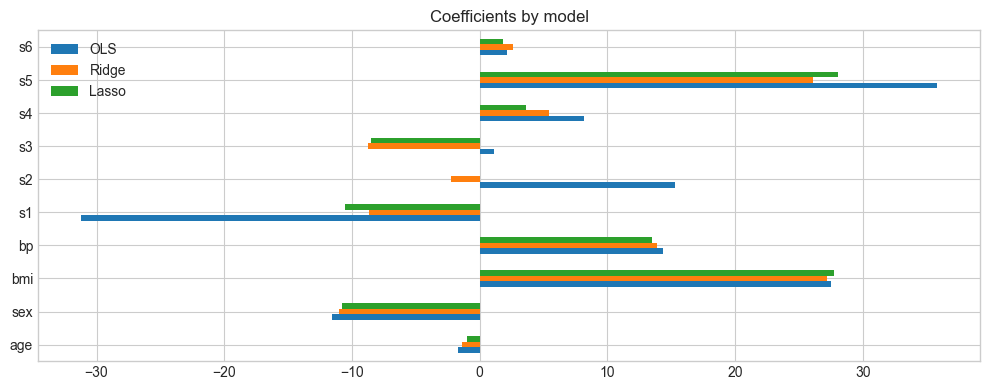

In [9]:
from sklearn.linear_model import LassoCV, lasso_path

lasso = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)).fit(X_train, y_train)
results["Lasso"] = cv_rmse(make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0)))
print(f"Lasso best alpha = {lasso[-1].alpha_:.3g},  CV RMSE: {results['Lasso']:.1f}")

coefs["Ridge"] = ridge_search.best_estimator_[-1].coef_
coefs["Lasso"] = lasso[-1].coef_
print("Features dropped by Lasso:", list(coefs.index[coefs["Lasso"] == 0]))
coefs.plot.barh(title="Coefficients by model");

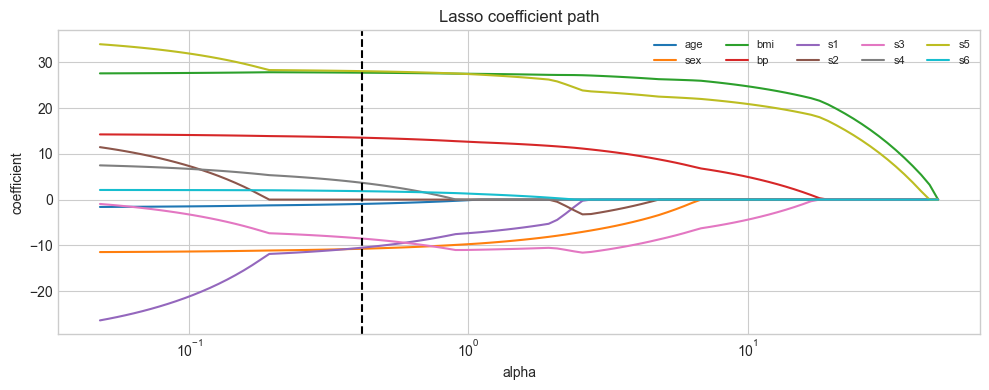

In [10]:
lasso_alphas, lasso_coefs, _ = lasso_path(X_std, y_train)
ax = pd.DataFrame(lasso_coefs.T, index=lasso_alphas, columns=X.columns).plot(logx=True, title="Lasso coefficient path")
ax.axvline(lasso[-1].alpha_, ls="--", color="k")
ax.set(xlabel="alpha", ylabel="coefficient")
ax.legend(ncol=5, fontsize=8);

## 6. PCA + OLS (principal component regression)
PCA turns correlated features into uncorrelated components ordered by variance, and you keep the first *k*.

Strictly, this is **dimensionality reduction rather than feature selection**. Each component mixes all the original features.
Also, PCA ignores the target, so high-variance components aren't guaranteed to be predictive. Choose *k* by CV, not by variance alone.

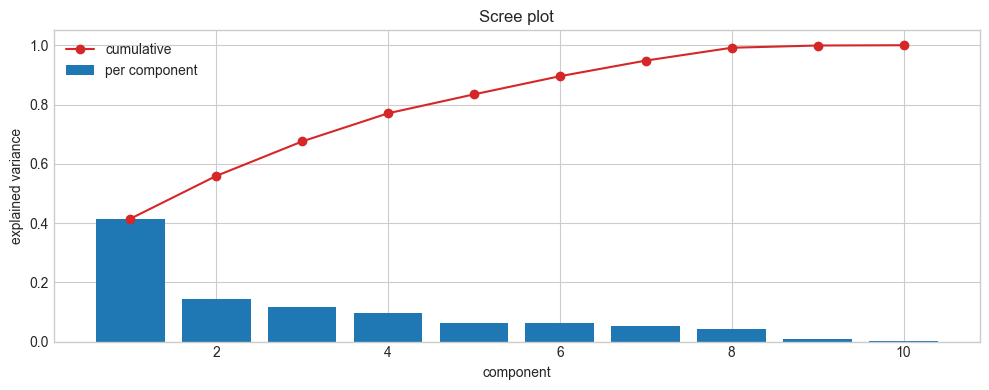

In [11]:
from sklearn.decomposition import PCA

pca = PCA().fit(X_std)
fig, ax = plt.subplots()
ax.bar(range(1, 11), pca.explained_variance_ratio_, label="per component")
ax.plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_), "o-", color="C3", label="cumulative")
ax.set(xlabel="component", ylabel="explained variance", title="Scree plot")
ax.legend();

Best k = 8, CV RMSE: 53.6


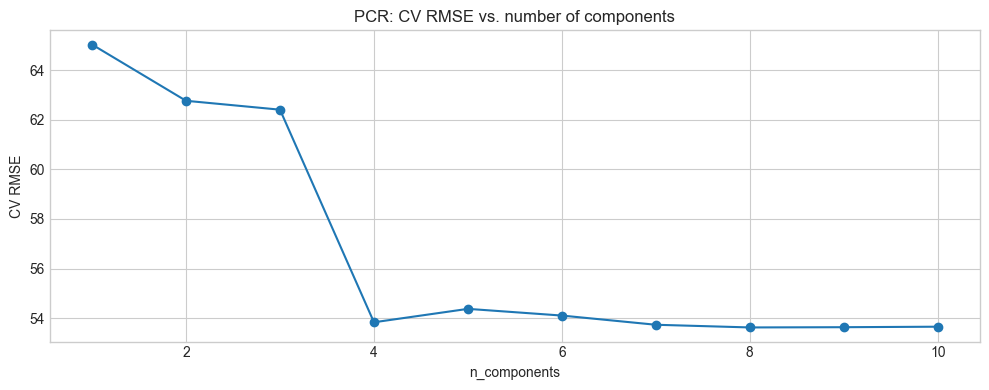

In [12]:
pcr_search = GridSearchCV(
    make_pipeline(StandardScaler(), PCA(), LinearRegression()),
    param_grid={"pca__n_components": range(1, 11)},
    cv=5, scoring="neg_root_mean_squared_error",
).fit(X_train, y_train)

cv_by_k = -pd.Series(pcr_search.cv_results_["mean_test_score"], index=range(1, 11))
cv_by_k.plot(marker="o", title="PCR: CV RMSE vs. number of components", xlabel="n_components", ylabel="CV RMSE")

k = pcr_search.best_params_["pca__n_components"]
results[f"PCA({k}) + OLS"] = -pcr_search.best_score_
print(f"Best k = {k}, CV RMSE: {results[f'PCA({k}) + OLS']:.1f}")

**What's in a component?** The loadings show how much each original feature contributes.

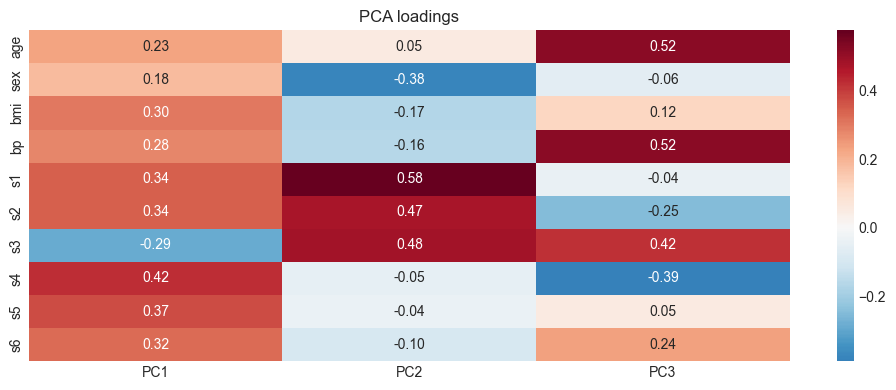

In [13]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f")
plt.title("PCA loadings");

## 7. Compare → final test score
Choose the model by CV, then score it on the test set **once**.

In [14]:
pd.Series(results, name="CV RMSE").sort_values().to_frame()

,CV RMSE
Ridge,53.575361
PCA(8) + OLS,53.625679
OLS,53.655277
Lasso,53.724554


Test RMSE: 58.6   R²: 0.330


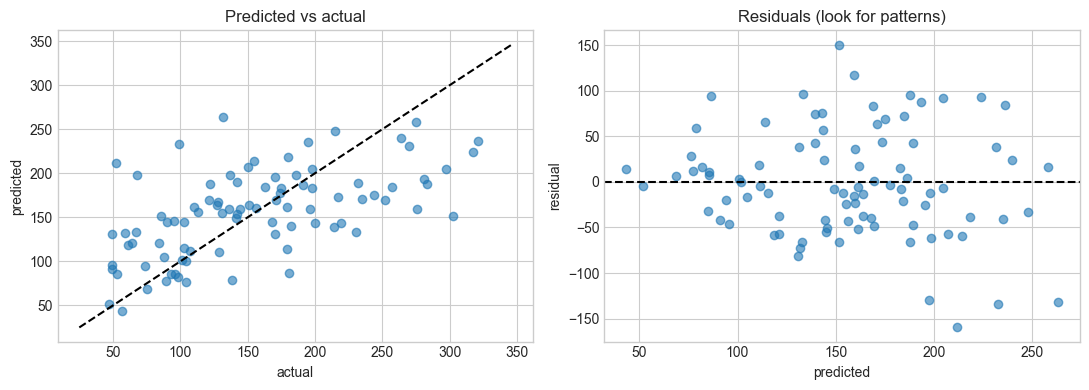

In [15]:
final = lasso   # or ridge_search.best_estimator_, pcr_search.best_estimator_, ...
y_pred = final.predict(X_test)
print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred):.1f}   R²: {r2_score(y_test, y_pred):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(y_test, y_pred, alpha=0.6); ax1.plot([y.min(), y.max()], [y.min(), y.max()], "k--")
ax1.set(xlabel="actual", ylabel="predicted", title="Predicted vs actual")
ax2.scatter(y_pred, y_test - y_pred, alpha=0.6); ax2.axhline(0, color="k", ls="--")
ax2.set(xlabel="predicted", ylabel="residual", title="Residuals (look for patterns)");

**Takeaways**
- Scale first. Penalties and PCA depend on feature scale, and putting the scaler in a pipeline prevents leakage.
- **Ridge** is for many correlated features that all matter a little. **Lasso** is for when you suspect only a few matter, since it drops the rest.
  `ElasticNetCV` blends the two.
- **PCA** helps when features are highly collinear or too numerous. Choose *k* by CV, and remember you give up interpretability.
- On a small, clean dataset like this one, the models score close together. Regularization matters more as the number of features grows relative to the number of rows.